# 0. Setup Environment

In [1]:
import torch
from torch import nn

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. 标准RNN

标准RNN中, 每一个时间步的输出取决于:
1. 上一时间步的隐藏状态
2. 当前时间步的输入

公式:
$$
h_t = f(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh}) \\
$$
其中， $x_t$ 是当前时间步的输入， $h_{t-1}$ 是上一时间步的隐藏状态， $W_{ih}$ 和 $W_{hh}$ 分别是输入到隐藏层和隐藏层到隐藏层的权重矩阵， $b_{ih}$ 和 $b_{hh}$ 是偏置项， $f$ 是激活函数（通常是 tanh 或 ReLU）

In [3]:
# 使用pytorch创建一个rnn
simple_rnn = nn.RNN(input_size=10, # 输入特征的维度, 即当前的输入x做embedding之后的维度
                    hidden_size=20, # 隐藏状态的维度
                    num_layers=2, 
                    nonlinearity='tanh', 
                    batch_first=False, 
                    dropout=0.0)

In [4]:
simple_rnn

RNN(10, 20, num_layers=2)

In [5]:
# 输入input的形状应该为: (seq_len, batch, input_size) 
# 如果是batch_first, 那就是 (batch, seq_len, input_size)
seq_len = 6
batch_size = 3
feature_size = 10
test_input = torch.randn(seq_len, batch_size, feature_size)
output, h_n = simple_rnn(test_input)
print("Output shape:", output.shape)  # 输出的形状
print("Hidden state shape:", h_n.shape)  # 隐藏状态的形状
# output是rnn的所有时间步最后一层的隐藏状态, 形状为 (seq_len, batch, hidden_size)
# h_n是最后一个时间步的各个层的隐藏状态, 形状为 (num_layers, batch, hidden_size)
# 输入还可以传入一个h_0, 如果不传, 默认为0

Output shape: torch.Size([6, 3, 20])
Hidden state shape: torch.Size([2, 3, 20])


In [6]:
output[-1] == h_n[-1]
# 左: 所有时间的最后一层的状态, 取最后一个时间步
# 右: 最后一个时间步的所有层的状态, 取最后一层

tensor([[True, True, True, True, True, True, True, True, True, True, True, True,
         True, True, True, True, True, True, True, True],
        [True, True, True, True, True, True, True, True, True, True, True, True,
         True, True, True, True, True, True, True, True],
        [True, True, True, True, True, True, True, True, True, True, True, True,
         True, True, True, True, True, True, True, True]])

# 2. LSTM

LSTM使用了输入门\输出门\遗忘门来控制信息的流动，从而解决了标准RNN在长序列中容易出现梯度消失的问题

In [7]:
seq_len = 6
batch_size = 3
feature_size = 10

simple_lstm = nn.LSTM(input_size=feature_size, # 输入特征的维度, 即当前的输入x做embedding之后的维度
                      hidden_size=10, # 隐藏状态的维度
                      num_layers=2,
                      batch_first=False,
                      dropout=0.0)

output, (h_n, c_n) = simple_lstm(torch.randn(seq_len, batch_size, feature_size))
print("Output shape:", output.shape)  # 输出的形状
print("Hidden state shape:", h_n.shape)  # 隐藏状态的形状
print("Cell state shape:", c_n.shape)  # 细胞状态的形状

Output shape: torch.Size([6, 3, 10])
Hidden state shape: torch.Size([2, 3, 10])
Cell state shape: torch.Size([2, 3, 10])


# 3. LSTM案例: 序列预测

数据是 1949-01 到 1960-12 的飞机月流量, 共 144 个月, 需要用之前的流量预测之后的流量

序列有明显的上升趋势和 12 个月的季节性周期

本次设定: 用前 seq_len 个月预测下 1 个月

In [8]:
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torch import Tensor
import pandas as pd
import numpy as np

DATA_ROOT_FOLDER = Path("data")
DATA_PATH = DATA_ROOT_FOLDER / "time_series.csv"

BATCH_SIZE = 1
TRAIN_RATIO = 0.7
SEQ_LEN = 12            # 用一个完整年周期预测下一个月 (原为 2)

HIDDEN_SIZE = 4
NUM_LAYERS = 2
LEARNING_RATE = 0.01
EPOCHS = 60
RANDOM_SEED = 42

In [9]:
df = pd.read_csv(DATA_PATH).dropna()
df.columns = ["Month", "Passengers"]  # 原第二列列名很长且含 '?', 按位置重命名(不改动 CSV 文件)
df

,Month,Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0
...,...,...
139,1960-08,606.0
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0


In [10]:
class CSVDataset(Dataset):
    """把一维时间序列切成 (前 seq_len 个月 -> 下 1 个月) 的样本"""

    def __init__(self, series,
                 min_value: float, 
                 scale: float, 
                 seq_len: int = 2):
        series = np.asarray(series, dtype="float32")
        self.min_value = min_value
        self.scale = scale
        self.seq_len = seq_len
        # 整体归一化一次, __getitem__ 里只做切片
        self.series = (series - self.min_value) / self.scale

    def __len__(self) -> int:
        # 最后一个样本的 target 正好是序列的最后一个点
        return len(self.series) - self.seq_len

    def __getitem__(self, index: int):
        x = self.series[index: index + self.seq_len]            # (seq_len,)
        y = self.series[index + self.seq_len]                   # 标量
        x = torch.tensor(x, dtype=torch.float32).unsqueeze(-1)  # (seq_len, 1) 补上特征维
        y = torch.tensor([y], dtype=torch.float32)              # (1,) 与模型输出形状对齐
        return x, y

In [11]:
def generate_dataset(data_path, seq_len=2, train_ratio=0.7, batch_size=1) -> tuple[CSVDataset, CSVDataset, DataLoader, DataLoader]:
    df = pd.read_csv(data_path).dropna()
    df.columns = ["Month", "Passengers"]  # 原第二列列名很长且含 '?', 按位置重命名
    series = df["Passengers"].to_numpy(dtype="float32")

    train_size = int(len(series) * train_ratio)
    train_raw, test_raw = series[:train_size], series[train_size:]

    min_value = float(train_raw.min())
    scale = float(train_raw.max() - train_raw.min())

    train_dataset = CSVDataset(train_raw, min_value, scale, seq_len)
    test_dataset = CSVDataset(test_raw, min_value, scale, seq_len)

    # 训练集可以打乱: 切分已按时间做过, 训练窗口全部严格早于测试窗口, 且模型不在样本间传递 hidden state
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    # 测试集必须保持时间顺序, 否则预测结果无法对齐月份画图
    test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    return train_dataset, test_dataset, train_dataloader, test_dataloader

In [12]:
train_dataset, test_dataset, train_dataloader, test_dataloader = generate_dataset(
    DATA_PATH, seq_len=SEQ_LEN, train_ratio=TRAIN_RATIO, batch_size=BATCH_SIZE)

print("训练集样本数:", len(train_dataset))  # 100 - 12 = 88
print("测试集样本数:", len(test_dataset))   # 44 - 12 = 32
print("归一化参数(只在训练段拟合): min =", train_dataset.min_value, ", scale =", train_dataset.scale)
print("测试集复用的是同一组:       ", test_dataset.min_value, test_dataset.scale)

# 两段共用同一组参数, 显式取出来方便下面复用
MIN_VALUE = train_dataset.min_value
SCALE = train_dataset.scale


def inverse_transform(y_scaled):
    """把归一化空间的值还原成真实乘客数"""
    return y_scaled * SCALE + MIN_VALUE


def evaluate_mae(model, dataloader):
    """返回真实单位(千人次)的平均绝对误差"""
    model.eval()
    total, n = 0.0, 0
    with torch.inference_mode():
        for X, Y in dataloader:
            pred = inverse_transform(model(X))   # (batch, 1)
            true = inverse_transform(Y)          # (batch, 1)
            total += (pred - true).abs().sum().item()
            n += Y.shape[0]
    return total / n


def persistence_mae(dataset):
    """朴素基线: 直接用窗口最后一个月的值预测下一个月"""
    last = dataset.series[dataset.seq_len - 1: -1]   # 每个窗口的最后一个值
    target = dataset.series[dataset.seq_len:]        # 每个窗口的 target
    assert len(last) == len(target) == len(dataset)
    return float(np.abs(last - target).mean() * dataset.scale)

训练集样本数: 88
测试集样本数: 32
归一化参数(只在训练段拟合): min = 104.0 , scale = 309.0
测试集复用的是同一组:        104.0 309.0


In [13]:
for X, Y in train_dataloader:
    print("X shape:", X.shape)  # (batch, seq_len, 1)
    print("Y shape:", Y.shape)  # (batch, 1)
    break

# 注意最后一维才是特征数(单变量序列 = 1), 中间那维是 seq_len
# nn.LSTM 的 input_size 必须等于 X.shape[-1] = 1
print("input_size 应为 X.shape[-1] =", X.shape[-1], ", 而 seq_len =", X.shape[1])

X shape: torch.Size([1, 12, 1])
Y shape: torch.Size([1, 1])
input_size 应为 X.shape[-1] = 1 , 而 seq_len = 12


In [14]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size: int = 1, hidden_size: int = 4,
                 output_size: int = 1, num_layers: int = 2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size,  # 必须等于 X.shape[-1] (特征数)
                            hidden_size=hidden_size,
                            num_layers=num_layers,
                            batch_first=True)
        self.regression = nn.Linear(hidden_size, output_size)  # 多对一: 只输出一个值

    def forward(self, X: Tensor):
        output, _ = self.lstm(X)  # output: (batch, seq_len, hidden_size)
        # 取最后一个时间步的输出: (batch, seq_len, hidden) -> (batch, hidden)
        return self.regression(output[:, -1, :])  # (batch, output_size)

In [15]:
def train_lstm(model: LSTMRegressor, train_dataloader: DataLoader,
               loss_fn, optimizer, epochs=100):
    """每个 epoch 训练完, 在测试集上评估一次并记录"""
    history = {"train_mse": [], "train_mae": [], "test_mse": [], "test_mae": []}

    for epoch in range(epochs):
        model.train()
        train_mse = 0.0
        for X, Y in train_dataloader:
            output = model(X)
            loss = loss_fn(output, Y)
            train_mse += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        train_mse /= len(train_dataloader)

        # 每个 epoch 都记, 否则曲线只有 10 个点, 而且 x 轴会被读成 epoch 0~9
        history["train_mse"].append(train_mse)
        history["train_mae"].append(evaluate_mae(model, train_dataloader))
        
        model.eval()
        with torch.inference_mode():
            test_mse = 0.0
            for X, Y in test_dataloader:
                output = model(X)
                loss = loss_fn(output, Y)
                test_mse += loss.item()
            test_mse /= len(test_dataloader)
            history["test_mse"].append(test_mse)
            history["test_mae"].append(evaluate_mae(model, test_dataloader))

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}/{epochs}  train MSE {train_mse:.6f}  "
                  f"train MAE {history['train_mae'][-1]:6.1f}  (千人次)")
            print(f"Epoch {epoch + 1}/{epochs}  test MSE {test_mse:.6f}  "
                  f"test MAE {history['test_mae'][-1]:6.1f}  (千人次)")
            print()

    return history

In [16]:
# 每次运行本单元格都从头训练, 避免在上一次训练过的权重上接着训
torch.manual_seed(RANDOM_SEED)
lstm_net = LSTMRegressor(input_size=1, hidden_size=HIDDEN_SIZE,
                         output_size=1, num_layers=NUM_LAYERS)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_net.parameters(), lr=LEARNING_RATE)

history = train_lstm(lstm_net, train_dataloader, loss_fn, optimizer, epochs=EPOCHS)

Epoch 10/60  train MSE 0.012734  train MAE   36.5  (千人次)
Epoch 10/60  test MSE 0.091319  test MAE   71.2  (千人次)



Epoch 20/60  train MSE 0.006500  train MAE   18.2  (千人次)
Epoch 20/60  test MSE 0.055715  test MAE   58.3  (千人次)



Epoch 30/60  train MSE 0.006543  train MAE   19.8  (千人次)
Epoch 30/60  test MSE 0.103182  test MAE   81.1  (千人次)



Epoch 40/60  train MSE 0.006454  train MAE   20.1  (千人次)
Epoch 40/60  test MSE 0.048556  test MAE   55.0  (千人次)



Epoch 50/60  train MSE 0.006392  train MAE   19.3  (千人次)
Epoch 50/60  test MSE 0.040400  test MAE   47.5  (千人次)



Epoch 60/60  train MSE 0.006129  train MAE   19.5  (千人次)
Epoch 60/60  test MSE 0.047239  test MAE   51.7  (千人次)



看这张图要问两个问题:

1. **红线(test MAE)有没有低于灰线(persistence 基线)?** 没有的话, 模型比不上"上个月多少就猜多少", 等于什么都没学到。
2. **蓝线(train MAE)比红线低多少?** 差得越多, 说明越只是在训练集上拟合。

还要注意两件事:

- 图上**没有验证集**, 所以蓝线不能用来说明泛化能力, 只有那条只评估一次的红线能。
- 曲线的抖动不是随机噪声: `batch_size=1` 时每个 epoch 做 88 次更新, epoch 末尾的权重受 shuffle 顺序影响很大; 而测试集里超过一半的目标落在训练段取值范围之外, 模型对外推区间的输出本来就敏感。

In [17]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

def plot_mae_curve(history, test_dataset):
    plt.figure(figsize=(10, 5))
    plt.plot(history["train_mae"], label="Train MAE")
    plt.plot(history["test_mae"], label="Test MAE")
    plt.axhline(y=persistence_mae(test_dataset), color='r', linestyle='--', label="Persistence MAE")
    plt.title("MAE Curve")
    plt.xlabel("Epochs")
    plt.ylabel("MAE (千人次)")
    plt.legend()
    plt.grid()
    plt.show()

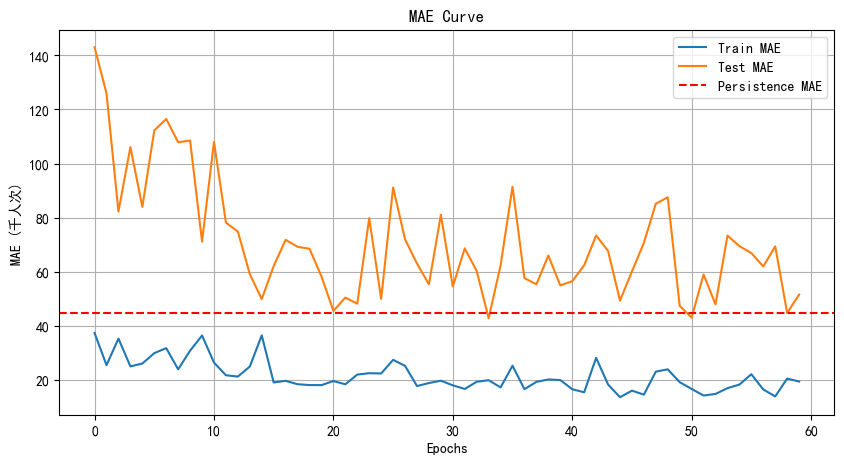

In [18]:
plot_mae_curve(history, test_dataset)

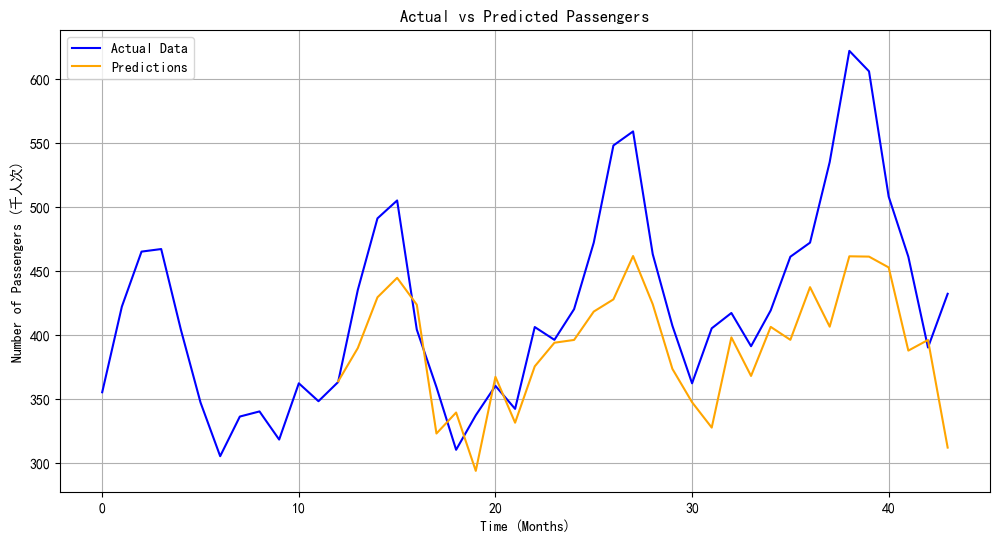

In [19]:
# 绘制实际数据和预测数据的对比图
def plot_predictions(model, dataset):
    model.eval()
    predictions = []
    with torch.inference_mode():
        for X, _ in DataLoader(dataset, batch_size=1, shuffle=False):
            pred = inverse_transform(model(X)).item()
            predictions.append(pred)

    plt.figure(figsize=(12, 6))
    plt.plot(range(len(dataset.series)), inverse_transform(dataset.series), label="Actual Data", color='blue')
    plt.plot(range(dataset.seq_len, len(dataset.series)), predictions, label="Predictions", color='orange')
    plt.title("Actual vs Predicted Passengers")
    plt.xlabel("Time (Months)")
    plt.ylabel("Number of Passengers (千人次)")
    plt.legend()
    plt.grid()
    plt.show()

plot_predictions(lstm_net, test_dataset)

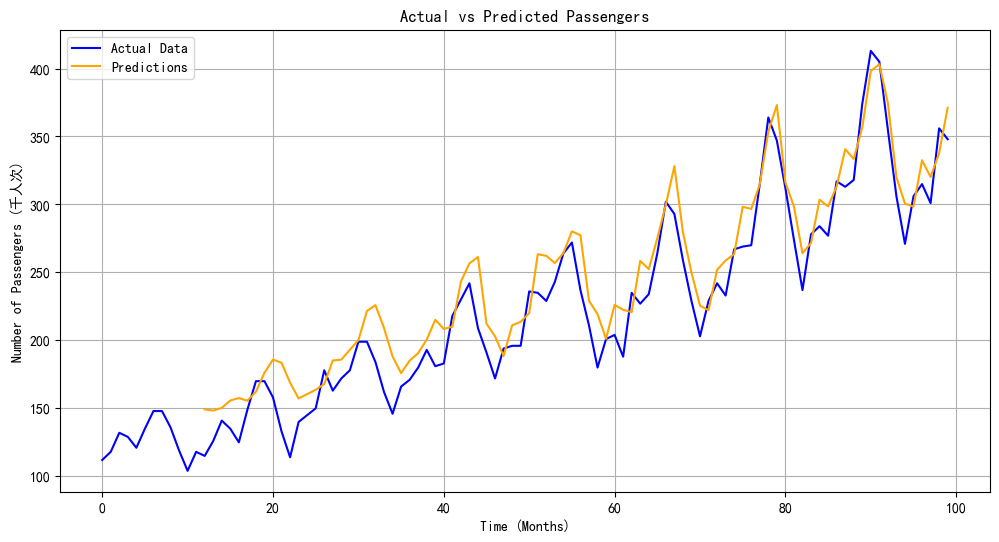

In [20]:
plot_predictions(lstm_net, train_dataset)

# 4. NLP案例: 情感分析

## 下载imdb数据集, 训练一个LSTM模型来预测电影评论的情感(正面或负面)

In [21]:
# 第 4 节要能独立运行, 所以自己 import 需要的模块
# (第 3 节也 import 过 Dataset/DataLoader, 但那是第 3 节的事)
import torch
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

dataset_hf = load_dataset("stanfordnlp/imdb")
train_raw = dataset_hf["train"]
test_raw = dataset_hf["test"]

In [22]:
dataset_hf

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [23]:
train_raw

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [24]:
train_raw[0]

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [25]:
set(train_raw["label"])

{0, 1}

In [26]:
# 最长的文本长度
max(len(item["text"]) for item in train_raw)

13704

In [27]:
all_texts = [item["text"] for item in train_raw]
all_texts[:5]

['I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, e

## 训练分词器

In [28]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace

tokenizer = Tokenizer(BPE(unk_token="[UNK]")) # BPE算法, 遇到不在词表里的词, 用[UNK]代替
tokenizer.pre_tokenizer = Whitespace() # 训练之前, 先按空格分割文本
trainer = BpeTrainer(vocab_size=10000, # 词表大小
                     special_tokens=["[UNK]", "[PAD]"] # 特殊符号, [PAD]用于补齐短文本, [UNK]用于替换不在词表里的词
                     )
tokenizer.train_from_iterator(all_texts, trainer=trainer) # 训练分词器

In [29]:
pad_id = tokenizer.token_to_id("[PAD]")
pad_id

1

In [30]:
tokenizer.token_to_id(token= "inspired")

3097

## 文本预处理

In [31]:
MAX_LEN = 512 # 序列长度, 超过的截断, 不足的补[PAD]
              # IMDB 评论 token 数中位数是 234

def text2ids(text: str):
    """把文本转成id序列, 并补齐或截断到固定长度"""
    ids = tokenizer.encode(text).ids
    if len(ids) > MAX_LEN:
        return ids[:MAX_LEN]  # 截断
    else:
        # 左填充: [PAD] 补在前面。模型取 lstm_out[:, -1, :]
        return [pad_id] * (MAX_LEN - len(ids)) + ids

In [32]:
test_text_encode = tokenizer.encode(sequence= all_texts[0])
test_text_encode

Encoding(num_tokens=382, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

In [33]:
test_text_encode.ids[:5], test_text_encode.type_ids[:5], test_text_encode.tokens[:5]

([44, 3867, 44, 3787, 38], [0, 0, 0, 0, 0], ['I', 'rented', 'I', 'AM', 'C'])

## 自定义dataset

In [34]:
class SentimentDataset(Dataset):
    def __init__(self, data):
        self.data = data
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, index):
        text = self.data[index]["text"]
        label = self.data[index]["label"]
        ids = text2ids(text)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(label, dtype=torch.long)

In [35]:
def createDatasets(train_data, test_data, batch_size=32, shuffle_train=True):
    train_dataset = SentimentDataset(train_data)
    test_dataset = SentimentDataset(test_data)
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=shuffle_train)
    test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_dataset, test_dataset, train_dataloader, test_dataloader

In [36]:
BATCH_SIZE = 32
train_dataset, test_dataset, train_dataloader, test_dataloader = createDatasets(train_raw, 
                                                                                test_raw, 
                                                                                batch_size=BATCH_SIZE)

In [37]:
train_dataset[0]

(tensor([   1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
            1,    1,    1,    1,    1,    1,    1,    1,    1,    1,   44, 3867,
           44, 3787,   38,   56, 4593,   50, 1797,   16,   60, 4435, 2430,   58,
          330,  360, 1334, 2

In [38]:
for X, Y in train_dataloader:
    print("X shape:", X.shape)  # (batch, seq_len)
    print("Y shape:", Y.shape)  # (batch,)
    break

X shape: torch.Size([32, 512])
Y shape: torch.Size([32])


## 定义模型

In [39]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings= vocab_size, # 词表大小(有多少词)
                                      embedding_dim= embedding_dim, # 每个词的向量维度
                                      padding_idx=pad_id # 补齐符号的id, 让embedding层忽略这个id的embedding, 不参与训练
                                      )
        self.lstm = nn.LSTM(input_size=embedding_dim,
                            hidden_size=hidden_size,
                            num_layers=num_layers,
                            batch_first=True,
                            dropout=dropout
                            )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 2) # 二分类
        
    def forward(self, X: torch.Tensor):
        # X: (batch, seq_len)
        embedded = self.embedding(X) # (batch, seq_len, embedding_dim)
        lstm_out, _ = self.lstm(embedded) # (batch, seq_len, hidden_size)
        lstm_out = self.dropout(lstm_out)
        # 取最后一个时间步的输出
        last_output = lstm_out[:, -1, :] # (batch, hidden_size)
        logits = self.fc(last_output) # (batch, 2)
        return logits

In [40]:
vocab_size = tokenizer.get_vocab_size()
vocab_size

10000

In [41]:
test_embedding = nn.Embedding(vocab_size, 4, pad_id)
test_text = train_dataset[0][0]
res = test_embedding(test_text)
test_text.shape, res.shape, res[:5]

(torch.Size([512]),
 torch.Size([512, 4]),
 tensor([[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]], grad_fn=<SliceBackward0>))

## 创建模型

In [42]:
device = "cuda" if torch.cuda.is_available() else "cpu"

EMBEDDING_DIM = 128
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.3
LEARNING_RATE = 0.001

loss_fn = nn.CrossEntropyLoss()

# 形状自检: (batch, MAX_LEN) -> (batch, 2)
# 这里只建一次性实例; 真正的模型在训练格里创建, 这样重跑训练格是从头训练
_check = SentimentLSTM(vocab_size=vocab_size,
                       embedding_dim=EMBEDDING_DIM,
                       hidden_size=HIDDEN_SIZE,
                       num_layers=NUM_LAYERS,
                       dropout=DROPOUT)
_xb, _yb = next(iter(train_dataloader))
print("logits:", _check(_xb).shape, " label:", _yb.shape)   # (32, 2) / (32,)

logits: torch.Size([32, 2])  label: torch.Size([32])


In [43]:
from tqdm.auto import tqdm

def get_accuracy(logits: torch.Tensor, labels):
    return (logits.argmax(dim=1) == labels).sum().item() / labels.shape[0] * 100

def train(model: SentimentLSTM, epochs: int,
          train_dataloader: DataLoader,
          test_dataloader: DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: nn.Module,
          device):

    history = {"train_loss": [],
               "test_loss": [],
               "train_acc": [],
               "test_acc": []}
    
    for epoch in tqdm(range(epochs)):
        # ---------- 训练 ----------
        model.train()
        train_loss, train_acc, train_n = 0.0, 0.0, 0
        for X, y in train_dataloader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = loss_fn(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # 按样本数加权累加: 最后一批只有 8 条, 直接按 batch 求平均会有偏差
            train_loss += loss.item() * y.shape[0]
            train_acc += get_accuracy(logits, y) * y.shape[0]
            train_n += y.shape[0]
        train_loss /= train_n
        train_acc /= train_n 

        # ---------- 评估 ----------
        model.eval()
        test_loss, test_acc, test_n = 0.0, 0.0, 0
        with torch.inference_mode():
            for X, y in test_dataloader:
                X, y = X.to(device), y.to(device)
                logits = model(X)
                test_loss += loss_fn(logits, y).item() * y.shape[0]
                test_acc += get_accuracy(logits, y) * y.shape[0]
                test_n += y.shape[0]
        test_loss /= test_n
        test_acc /= test_n

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoch {epoch+1:2d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.3f}")
        print(f"Epoch {epoch+1:2d} | Test  Loss: {test_loss:.4f} | Test  Acc: {test_acc:.3f}")
        print()

    return history   # 原来没有这一行, history 每次都被丢掉了

def predict_sentiment(text):
    model.eval()
    ids = text2ids(text)
    x = torch.tensor([ids], dtype=torch.long).to(device)
    with torch.inference_mode():
        logits = model(x)
        pred = torch.argmax(logits, dim=1).item()
    return "正面" if pred ==1 else "负面"

In [44]:
RANDOM_SEED = 42
EPOCHS = 5

torch.manual_seed(RANDOM_SEED)
model = SentimentLSTM(vocab_size=vocab_size,
                      embedding_dim=EMBEDDING_DIM,
                      hidden_size=HIDDEN_SIZE,
                      num_layers=NUM_LAYERS,
                      dropout=DROPOUT).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = train(model, EPOCHS, train_dataloader, test_dataloader,
                optimizer, loss_fn, device)

print(f"\n最终 test acc = {history['test_acc'][-1]:.3f}")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch  1 | Train Loss: 0.6164 | Train Acc: 64.756
Epoch  1 | Test  Loss: 0.5323 | Test  Acc: 73.548



Epoch  2 | Train Loss: 0.5295 | Train Acc: 73.304
Epoch  2 | Test  Loss: 0.5007 | Test  Acc: 75.416



Epoch  3 | Train Loss: 0.4430 | Train Acc: 79.952
Epoch  3 | Test  Loss: 1.2194 | Test  Acc: 54.560



Epoch  4 | Train Loss: 0.3811 | Train Acc: 83.236
Epoch  4 | Test  Loss: 0.3561 | Test  Acc: 84.760



Epoch  5 | Train Loss: 0.2625 | Train Acc: 89.628
Epoch  5 | Test  Loss: 0.3519 | Test  Acc: 85.368


最终 test acc = 85.368


## 绘制图像

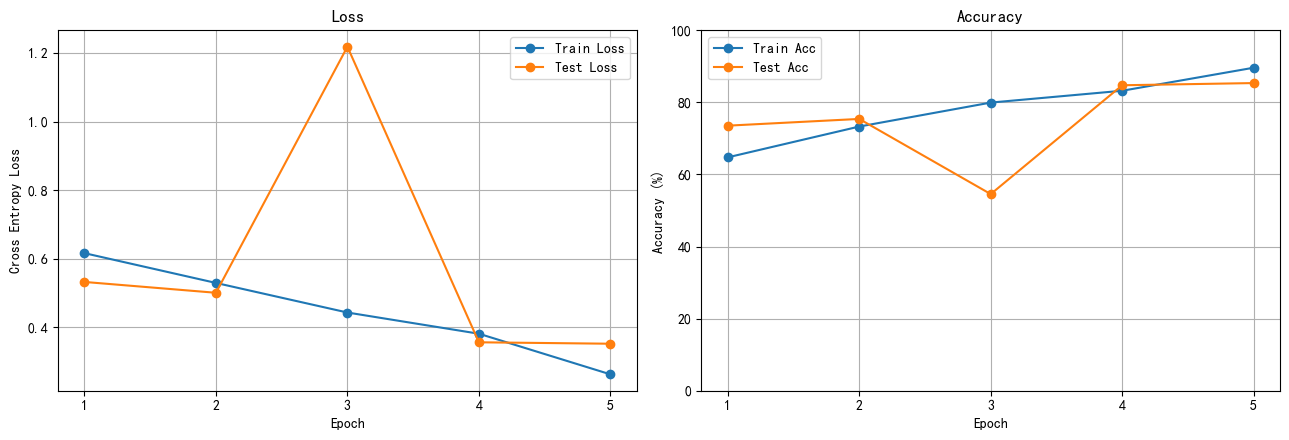

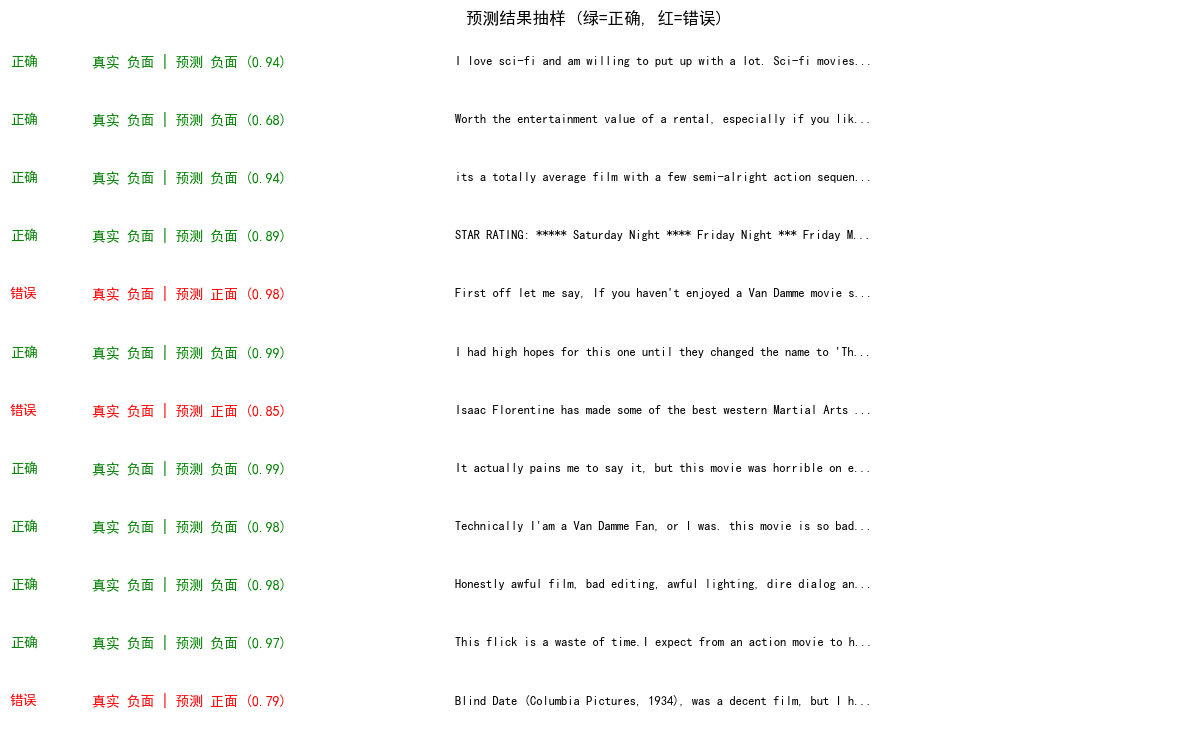

In [174]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

def plot_loss_acc_curves(history):
    """左图 loss, 右图 accuracy。每张图里两条曲线分别是 train 和 test。"""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
    ax1.plot(epochs, history["test_loss"], marker="o", label="Test Loss")
    ax1.set_title("Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Cross Entropy Loss")
    ax1.legend()
    ax1.grid()

    ax2.plot(epochs, history["train_acc"], marker="o", label="Train Acc")
    ax2.plot(epochs, history["test_acc"], marker="o", label="Test Acc")
    ax2.set_title("Accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy (%)")
    ax2.set_ylim(0, 100)        # get_accuracy 返回的是百分数(0~100), 不是 0~1
    ax2.legend()
    ax2.grid()

    for ax in (ax1, ax2):
        ax.set_xticks(list(epochs))   # epoch 是整数, 别画 1.5 这种刻度

    plt.tight_layout()
    plt.show()


def plot_predictions(model: SentimentLSTM, dataset: torch.utils.data.Dataset, n: int = 12):
    """抽 n 条样本, 显示真实标签 / 预测标签 / 置信度, 外加评论开头。

    dataset 是 SentimentDataset, 原始文本存在它的 .data 里。
    """
    model.eval()
    idx = list(range(min(n, len(dataset))))
    X = torch.stack([dataset[i][0] for i in idx]).to(device)
    y = torch.tensor([dataset[i][1] for i in idx])

    with torch.inference_mode():
        probs = torch.softmax(model(X), dim=1).cpu()
    conf, pred = probs.max(dim=1)

    names = {0: "负面", 1: "正面"}
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(idx) + 0.9))
    ax.axis("off")
    for row, i in enumerate(idx):
        yy = 1 - (row + 0.5) / len(idx)
        ok = pred[row].item() == y[row].item()
        color = "green" if ok else "red"

        text = dataset.data[i]["text"].replace("<br />", " ")   # IMDB 原文里的换行标记
        text = text[:64] + ("..." if len(text) > 64 else "")

        ax.text(0.00, yy, "正确" if ok else "错误", color=color, fontsize=10,
                family="SimHei", va="center", transform=ax.transAxes)
        ax.text(0.07, yy,
                f"真实 {names[y[row].item()]} | 预测 {names[pred[row].item()]} ({conf[row]:.2f})",
                color=color, fontsize=10, family="SimHei", va="center", transform=ax.transAxes)
        ax.text(0.38, yy, text, fontsize=9, family="SimHei", va="center",
                transform=ax.transAxes)

    ax.set_title("预测结果抽样 (绿=正确, 红=错误)", family="SimHei")
    plt.tight_layout()
    plt.show()


plot_loss_acc_curves(history)
plot_predictions(model, test_dataset)
